<a href="https://colab.research.google.com/github/ChrisSpell3/ISEN370_FA26_Team13_Project1.ipynb/blob/main/ISEN370_FA26_Team13_Project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ISEN 370 Project 1 Assignment
In this assignment, you will use data science tools to build basic statistics for a Building dataset.
You can use ISEN 370 Module 1 Project Demo file as a reference when completing this assignment.


First, you will need to import libraries to the project (note you should be able to find out the three libraries that need to be imported from the project demo file.) <br>
For your convenience, the first line has been provided below. Add two more lines to complete importing the libraries.

In [1]:
import numpy as np


In [2]:
import pandas as pd

In [3]:
import matplotlib.pyplot as plt

## Data Import

First, import the Building dataset and print the first 5 rows of data. The data is stored in a CSV file for which the path is given in the cell below.

In [4]:
data_url='https://raw.githubusercontent.com/StevenXJiang/ISEN370/refs/heads/main/VU_Building_Data_for_ISEN370_Spr_2020.csv'


## Exploring Data

Provide two lines of code below to read the csv data and display the first 5 rows of data.

In [5]:
# Read the dataset and display the first five rows.
try:
    data = pd.read_csv('ISEN370_Project1_Building_Data.csv')
except FileNotFoundError:
    data = pd.read_csv(data_url)
display(data.head())
print('Dataset shape:', data.shape)
print('Missing values by column:')
print(data.isna().sum())

,Time,Outside Air Temperature,Outside Air Relative Humidity,Solar Irradiation,Heating Water Flow Rate,Cooling Water Flow Rate,TotalEnergy
0,5/1/2019 6:00,74.948134,45.975163,652.0,11.470796,52.921483,2368.259398
1,5/1/2019 12:00,72.712222,58.188965,40175.0,12.899331,56.676044,2492.051721
2,5/1/2019 18:00,77.303218,50.842554,28088.0,12.541347,74.263546,2780.193712
3,5/2/2019 0:00,79.858004,47.440794,147.0,7.017166,64.022101,3356.955541
4,5/2/2019 6:00,67.272050,80.017084,855.0,13.038960,51.157088,2679.355667


Dataset shape: (491, 7)
Missing values by column:
Time                             0
Outside Air Temperature          0
Outside Air Relative Humidity    0
Solar Irradiation                0
Heating Water Flow Rate          0
Cooling Water Flow Rate          0
TotalEnergy                      0
dtype: int64


Display information about three variables: Heating Water Flow Rate,Cooling Water Flow Rate,and TotalEnergy.
Provide the code to display the top five rows of the data with these three features (columns).

In [6]:
features = data[['Heating Water Flow Rate', 'Cooling Water Flow Rate', 'TotalEnergy']]
display(features.head())

,Heating Water Flow Rate,Cooling Water Flow Rate,TotalEnergy
0,11.470796,52.921483,2368.259398
1,12.899331,56.676044,2492.051721
2,12.541347,74.263546,2780.193712
3,7.017166,64.022101,3356.955541
4,13.038960,51.157088,2679.355667


## Statistics Calculation

Calculate and print some of the basic statistics for each of the three features of the dataset selected above.
Be sure to include mean, minimum, maximum, and standard deviation and be sure to print it in such a way that it is clear what each number represents.
hint: use describe() function.

In [7]:
# Count, mean, standard deviation, minimum, quartiles, and maximum.
summary = features.describe().round(3)
display(summary)
# Explicitly label the four statistics requested in the assignment.
display(summary.loc[['mean', 'min', 'max', 'std']])

,Heating Water Flow Rate,Cooling Water Flow Rate,TotalEnergy
count,491.000,491.000,491.000
mean,6.026,64.031,2881.193
std,4.709,16.692,606.332
min,-0.178,8.878,362.734
25%,1.746,56.598,2646.716
50%,5.350,64.545,2947.976
75%,9.965,73.068,3218.448
max,13.520,113.429,4685.392


,Heating Water Flow Rate,Cooling Water Flow Rate,TotalEnergy
mean,6.026,64.031,2881.193
min,-0.178,8.878,362.734
max,13.520,113.429,4685.392
std,4.709,16.692,606.332


## Histogram Plotting
Plot a histogram for each of the three features of the dataset. Be sure to include proper titles and axis labels on each of your plots.

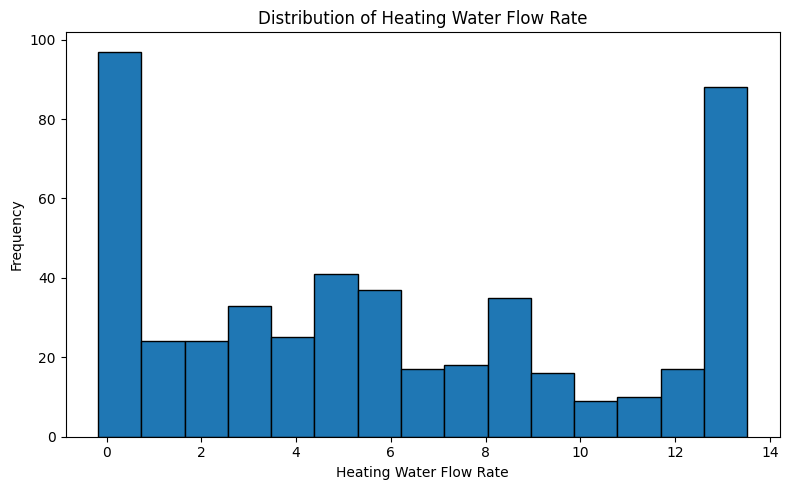

In [8]:
plt.figure(figsize=(8, 5))
plt.hist(features['Heating Water Flow Rate'], bins=15, edgecolor='black')
plt.xlabel('Heating Water Flow Rate')
plt.ylabel('Frequency')
plt.title('Distribution of Heating Water Flow Rate')
plt.tight_layout()
plt.show()

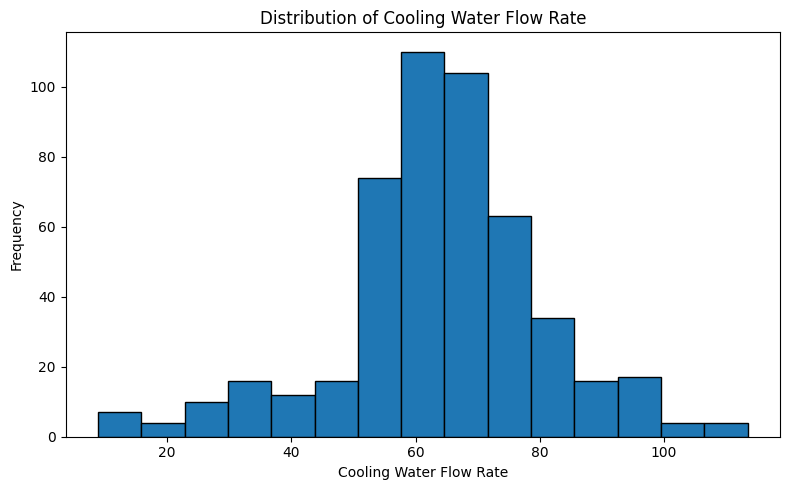

In [9]:
plt.figure(figsize=(8, 5))
plt.hist(features['Cooling Water Flow Rate'], bins=15, edgecolor='black')
plt.xlabel('Cooling Water Flow Rate')
plt.ylabel('Frequency')
plt.title('Distribution of Cooling Water Flow Rate')
plt.tight_layout()
plt.show()

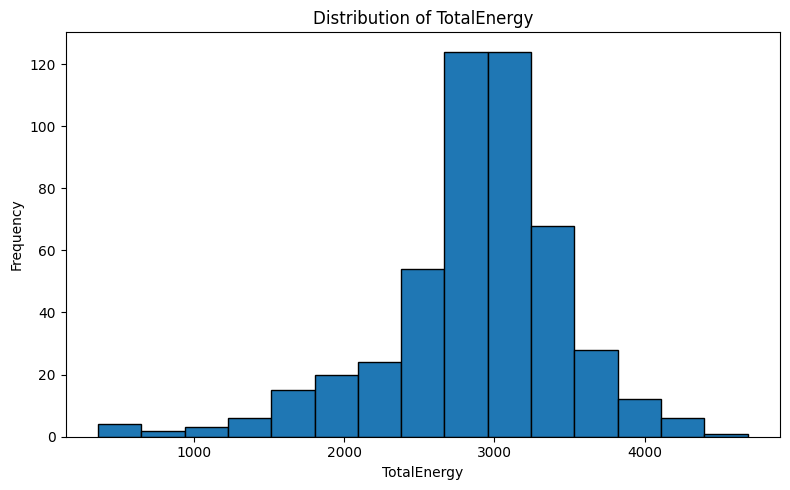

In [10]:
plt.figure(figsize=(8, 5))
plt.hist(features['TotalEnergy'], bins=15, edgecolor='black')
plt.xlabel('TotalEnergy')
plt.ylabel('Frequency')
plt.title('Distribution of TotalEnergy')
plt.tight_layout()
plt.show()

In [11]:
# Skewness helps describe distribution shape (positive = right skew, negative = left skew).
print('Skewness:')
print(features.skew().round(3))

Skewness:
Heating Water Flow Rate    0.259
Cooling Water Flow Rate   -0.395
TotalEnergy               -0.941
dtype: float64


**Question**

For each of the features, comment on the shape of the distribution.

Enter your answer in the text cell below:

***Heating Water Flow Rate:*** The distribution is spread across low and high flow values and is slightly right-skewed (skewness = 0.259). The mean (6.026) is a little higher than the median (5.350).

***Cooling Water Flow Rate:*** The distribution is concentrated near the middle of the observed range and is slightly left-skewed (skewness = -0.395). Its mean (64.031) is slightly below its median (64.545).

***TotalEnergy:*** The distribution is left-skewed (skewness = -0.941), with most observations at relatively higher energy values and a tail toward lower values. Its mean (2881.193) is lower than its median (2947.976).


## Scatter Plot

Create three scatter plots: the x axis for each plot is time and the y axis of the plot represents each of the three features.

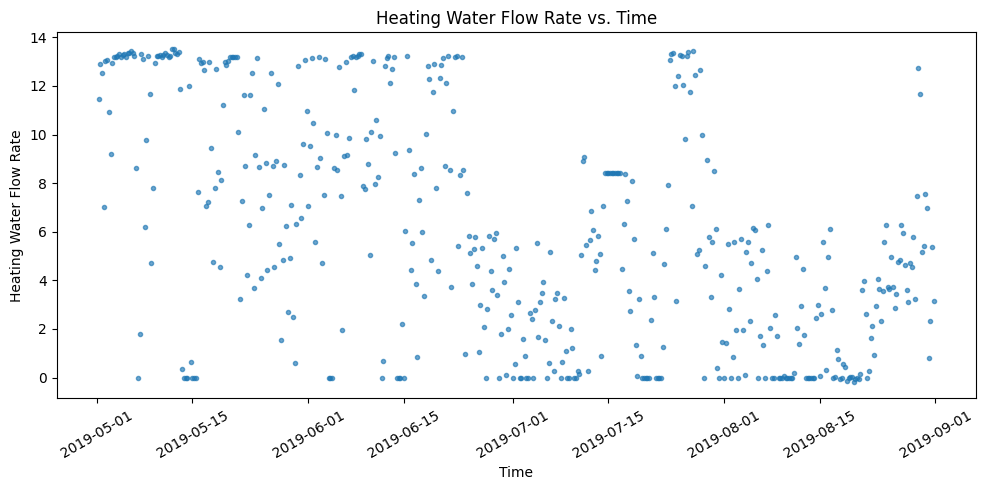

In [12]:
# Convert dates to datetime so the x-axis shows time chronologically.
time = pd.to_datetime(data['Time'])
plt.figure(figsize=(10, 5))
plt.scatter(time, data['Heating Water Flow Rate'], s=9, alpha=0.65)
plt.xlabel('Time')
plt.ylabel('Heating Water Flow Rate')
plt.title('Heating Water Flow Rate vs. Time')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

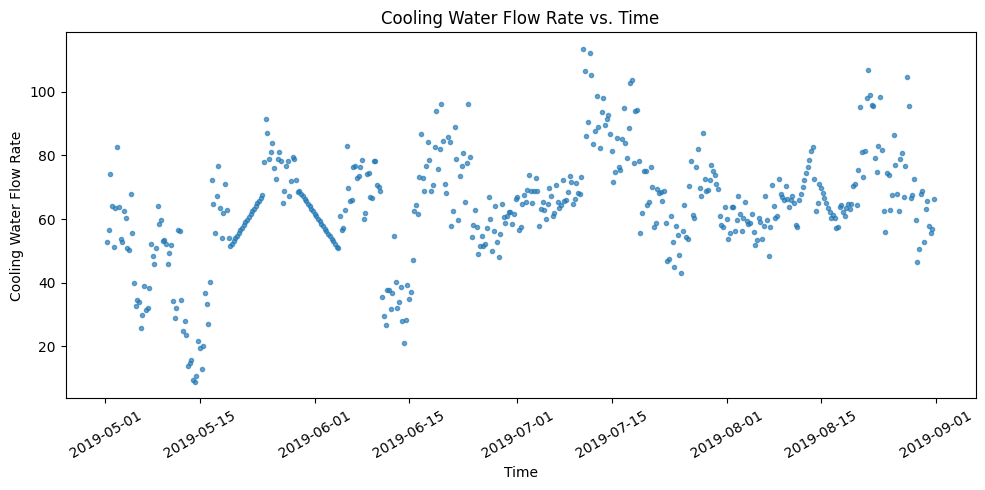

In [13]:
# Convert dates to datetime so the x-axis shows time chronologically.
time = pd.to_datetime(data['Time'])
plt.figure(figsize=(10, 5))
plt.scatter(time, data['Cooling Water Flow Rate'], s=9, alpha=0.65)
plt.xlabel('Time')
plt.ylabel('Cooling Water Flow Rate')
plt.title('Cooling Water Flow Rate vs. Time')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

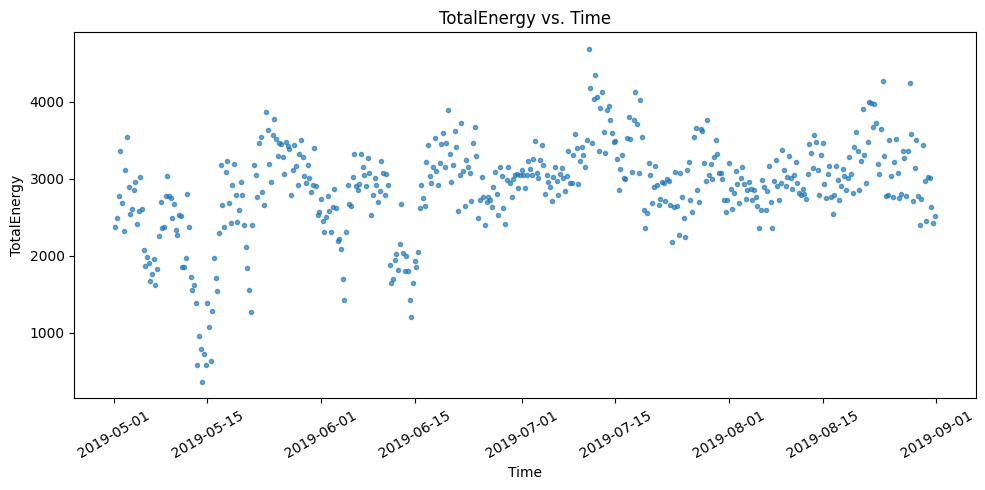

In [14]:
# Convert dates to datetime so the x-axis shows time chronologically.
time = pd.to_datetime(data['Time'])
plt.figure(figsize=(10, 5))
plt.scatter(time, data['TotalEnergy'], s=9, alpha=0.65)
plt.xlabel('Time')
plt.ylabel('TotalEnergy')
plt.title('TotalEnergy vs. Time')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In the spalce below, type your experience with your colab project experience. What you like, what you dislike and what you would like to experience in the future colab projects.

Working in Google Colab helped put into perspective how Python can quickly summarize building data and create graphs. Being able to compare the statistics with the histograms and time-based scatterplots. One challenge was making sure the CSV file loaded correctly and that the graphs had clear labels. In future projects, learning more about identifying unusual observations and comparing relationships between building variables would be a great interest.